# Agregación con cópulas, dependencia de cola y la asignación de Euler

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (la suma simple y la regla de la raíz cuadrada)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir qué es una cópula (teorema de Sklar), simular uniformes con la cópula gaussiana y la t de Student y explicar qué es la dependencia de cola, con la forma cerrada de los coeficientes de la t y de Clayton;
- convertir las cuatro marginales de Banco Andino en una simulación de las cuatro pérdidas y leer el VaR, la pérdida esperada en la cola y el capital económico de su suma;
- ver por qué la cópula t de Student exige más capital que la gaussiana con la misma correlación, y cuánto más con cada grado de libertad;
- repartir la pérdida esperada en la cola del total entre los cuatro riesgos con el principio de Euler, comprobar que las contribuciones suman exactamente, y compararlas con la asignación en forma cerrada de la regla de la raíz cuadrada;
- decir con honestidad cómo se produjeron las filas versionadas de la banda y qué reproduce y qué no reproduce la simulación de este cuaderno.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del cuaderno que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import euler
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import portfolio as port_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este cuaderno lee el mismo caso del cuaderno 01, **C18** (Banco Andino).

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (`outputs.aggregation`: las marginales, la matriz de correlación, el conjunto de grados de libertad, la banda versionada y la asignación de Euler versionada), `data/derived/C18/t-copula-baseline.json` (el mismo bloque con el estrés de la correlación mercado-crédito) y `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`: la función de cuantiles de cada una de las cuatro marginales sobre una grilla de probabilidades nombrada, contrato `c18-models` 3.0.0).
- **Cómo se hicieron las filas versionadas.** El pipeline construye una muestra de un millón de pérdidas para cada marginal con el motor (crédito: la cópula agrupada de los segmentos de C07; mercado: una t de Student ajustada al VaR y al ES de C11; riesgo de tasa de interés: la simulación de Hull-White de C15; riesgo operacional: la agregación de Fourier del generador de C17), entrega las cuatro funciones de cuantiles a `dependence_band` y versiona el resultado. **Las cuatro muestras no están versionadas, pero sí la función de cuantiles de cada marginal**, sobre una grilla nombrada: las 1.961 probabilidades $\Phi(z)$ para $z$ de -4,9 a 4,9 en pasos de 0,005, densas en ambas colas. El paso 3 reconstruye las cuatro marginales desde las grillas por interpolación lineal en la probabilidad, la regla que la agregación aplica a la muestra ordenada, y el paso 4 corre sobre ellas la agregación del propio pipeline con su semilla, así que se espera recuperar las filas versionadas casi al dígito. Las filas versionadas se imprimen siempre al lado de las del cuaderno.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


def sino(valor):
    # Mostrar un valor verdadero o falso como "sí" o "no"
    return "sí" if valor else "no"


print("carpeta derived encontrada:", sino(DERIVED.is_dir()))

baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
risks = [m["risk"] for m in agg["marginals"]]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
print("riesgos:", risks, "| conjunto de nu:", NU_SET, "| horneado con riskvalidation", baseline["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

carpeta derived encontrada: sí
riesgos: ['credit', 'market', 'irrbb', 'operational'] | conjunto de nu: [4.0, 8.0, 30.0] | horneado con riskvalidation 0.9.0 | instalado 0.9.0


## Método

### Paso 1: una cópula y su dependencia de cola

**Teorema de Sklar.** Toda distribución conjunta de pérdidas $L_1, \dots, L_d$ con funciones de distribución marginales $F_k$ se puede escribir $F(x_1, \dots, x_d) = C(F_1(x_1), \dots, F_d(x_d))$, donde la cópula $C$ lleva toda la dependencia y las $F_k$ llevan todo el comportamiento marginal. La agregación con cópula tiene entonces tres partes: elegir las marginales, elegir $C$ y simular $L_k = F_k^{-1}(U_k)$ con $U \sim C$ (dossier 05, G.1 ítem 3; McNeil, Frey y Embrechts 2015, cuyo número de capítulo es NO VERIFICADO en el dossier).

- **Cópula gaussiana** con matriz de correlación $R$: $U = \Phi(Z)$ con $Z \sim N(0, R)$ (Li 2000). No tiene dependencia de cola para $|\rho| < 1$: los extremos de dos riesgos se vuelven independientes lo bastante adentro de la cola.
- **Cópula t de Student** con $\nu$ grados de libertad: $U = t_\nu(X)$ con $X = \sqrt{\nu / \chi^2_\nu}\, Z$ (Frey y McNeil 2003; Demarta y McNeil 2005). Su **coeficiente de dependencia de cola** bivariado, el límite de $P(U_2 > q \mid U_1 > q)$ cuando $q \to 1$, es
$$\lambda = 2\, t_{\nu+1}\!\left(-\sqrt{\frac{(\nu+1)(1-\rho)}{1+\rho}}\right).$$
- **Cópula de Clayton** (bivariada): $C_\theta(u, v) = (u^{-\theta} + v^{-\theta} - 1)^{-1/\theta}$ con $\theta > 0$, y dependencia de cola inferior $\lambda_L = 2^{-1/\theta}$. El motor tiene las formas cerradas de Clayton pero no la muestrea (el docstring del módulo deja para después el muestreo de Clayton y las cópulas vine).

La celda siguiente evalúa el coeficiente de la t con la correlación mercado-crédito del caso (0,5) para cada grado de libertad del caso, y las formas cerradas de Clayton con tres valores de $\theta$.

In [3]:
# La dependencia de cola de la t con correlación 0,5 para cada nu del caso, y las formas cerradas de Clayton
for nu in NU_SET:
    print(f"cópula t, rho = 0.5, nu = {nu:4.0f}: dependencia de cola = {cop.t_tail_dependence(0.5, nu):.4f}")
print("cópula t, rho = 0.5, nu = 1000 (casi gaussiana):", format(cop.t_tail_dependence(0.5, 1000.0), ".2e"))
for theta in (0.5, 1.0, 2.0):
    print(f"Clayton theta = {theta}: C(0.5, 0.5) = {cop.clayton_copula(0.5, 0.5, theta):.4f} | dependencia de cola inferior = {cop.clayton_lower_tail_dependence(theta):.4f}")

cópula t, rho = 0.5, nu =    4: dependencia de cola = 0.2532
cópula t, rho = 0.5, nu =    8: dependencia de cola = 0.1173
cópula t, rho = 0.5, nu =   30: dependencia de cola = 0.0030
cópula t, rho = 0.5, nu = 1000 (casi gaussiana): 1.48e-64
Clayton theta = 0.5: C(0.5, 0.5) = 0.2991 | dependencia de cola inferior = 0.2500
Clayton theta = 1.0: C(0.5, 0.5) = 0.3333 | dependencia de cola inferior = 0.5000
Clayton theta = 2.0: C(0.5, 0.5) = 0.3780 | dependencia de cola inferior = 0.7071


### Paso 2: simular uniformes y medir la cola

`simulate_copula_uniforms(corr, family, nu, n, seed)` devuelve $n \times K$ uniformes con la cópula de la matriz `corr`. Ambas familias dan la misma correlación de rangos: la $\tau$ de Kendall de un par es $(2/\pi)\arcsin\rho$, 0,3333 para $\rho = 0,5$, así que un estadístico de rangos no distingue las cópulas. Lo que cambia es la esquina. La celda siguiente simula un millón de pares de cada cópula con $\rho = 0,5$, estima $P(U_2 > q \mid U_1 > q)$ en $q = 0,9; 0,99; 0,999$ contando, y compara con el límite del paso 1. La muestra tiene semilla, así que los números se repiten.

In [4]:
# Simular un millón de pares de la cópula gaussiana y de la t(4) con rho = 0,5 y contar excedencias conjuntas
pair = np.array([[1.0, 0.5], [0.5, 1.0]])
N_PAIRS = 1_000_000
draws = {"gaussiana": cop.simulate_copula_uniforms(pair, "gaussian", None, N_PAIRS, 7),
         "t (nu=4)": cop.simulate_copula_uniforms(pair, "t", 4.0, N_PAIRS, 7)}
print("tau de Kendall del par, teoría:", round(2 / np.pi * np.arcsin(0.5), 4))
for name, u in draws.items():
    tau = stats.kendalltau(u[:20_000, 0], u[:20_000, 1])[0]
    estimates = []
    for q in (0.9, 0.99, 0.999):
        first = u[:, 0] > q
        estimates.append(float((u[first, 1] > q).mean()))
    print(f"{name:9s} tau de Kendall (20000 pares): {tau:.4f} | P(U2 > q | U1 > q) en q = 0.9, 0.99, 0.999: {np.round(estimates, 4)}")
print("límite para la t(4):", round(cop.t_tail_dependence(0.5, 4.0), 4), "| límite para la gaussiana: 0")

tau de Kendall del par, teoría: 0.3333
gaussiana tau de Kendall (20000 pares): 0.3367 | P(U2 > q | U1 > q) en q = 0.9, 0.99, 0.999: [0.3222 0.1278 0.0552]
t (nu=4)  tau de Kendall (20000 pares): 0.3386 | P(U2 > q | U1 > q) en q = 0.9, 0.99, 0.999: [0.3849 0.2816 0.2784]
límite para la t(4): 0.2532 | límite para la gaussiana: 0


El gráfico muestra lo mismo: las dos nubes tienen el mismo centro y la misma $\tau$ de Kendall, pero la cópula t pone visiblemente más puntos en las esquinas superior derecha e inferior izquierda, que para pérdidas es la esquina donde los dos riesgos salen mal juntos.

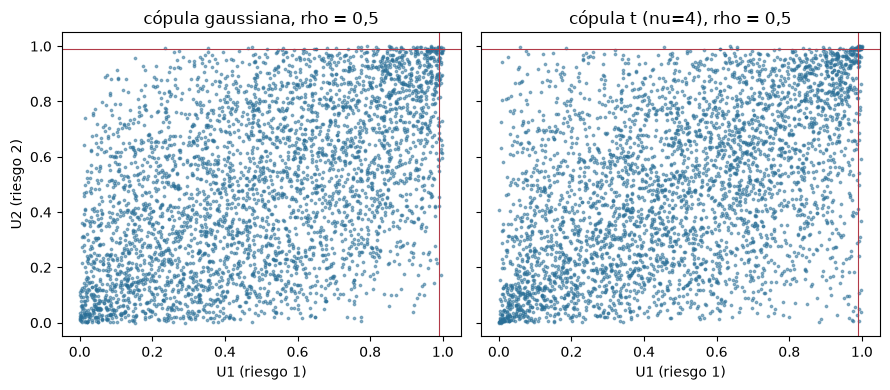

In [5]:
# Dibujar 4.000 pares de cada cópula, con la esquina de excedencia conjunta marcada
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, (name, u) in zip(axes, draws.items()):
    ax.scatter(u[:4000, 0], u[:4000, 1], s=3, alpha=0.5, color="#2a6f97")
    ax.axvline(0.99, color="#b23a48", linewidth=0.8)
    ax.axhline(0.99, color="#b23a48", linewidth=0.8)
    ax.set_title(f"cópula {name}, rho = 0,5")
    ax.set_xlabel("U1 (riesgo 1)")
axes[0].set_ylabel("U2 (riesgo 2)")
fig.tight_layout()
plt.show()

### Paso 3: las marginales

La cópula necesita una función de cuantiles $F_k^{-1}$ para cada riesgo, y el caso las versiona. Para cada marginal el documento de modelos guarda su cuantil en las probabilidades $\Phi(z)$, $z = -4{,}9; -4{,}895; \dots; 4{,}9$ (1.961 puntos, en millones de CLP), desde cerca de $5 \times 10^{-7}$ hasta $1 - 5 \times 10^{-7}$, el alcance de la primera y la última de las $10^6$ simulaciones. Entre dos puntos la función de cuantiles es lineal en la probabilidad y queda fija en los extremos, que es la regla de `marginal_ppf_sample` del motor aplicada a una muestra ordenada. No se ajusta nada: la forma de cada marginal, la cola pesada del riesgo operacional incluida, es la del pipeline.

La celda siguiente reconstruye las cuatro funciones de cuantiles, lee de cada una una muestra de $10^6$ posiciones de Hazen $(i - 0{,}5)/n$ e imprime el VaR, el ES y la media que leen los estimadores del motor junto al VaR, el ES y la pérdida esperada versionados.

In [6]:
# Reconstruir las cuatro marginales desde las grillas de cuantiles versionadas y comparar lo que el motor lee de ellas con el EL, VaR y ES versionados
LEVEL = 0.999
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
probs = np.array(grid["probabilities"])
draw_positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
for m, q in zip(agg["marginals"], grid["marginals"]):
    assert m["risk"] == q["risk"]
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(draw_positions, probs, quantiles)
print("grilla:", grid["convention"]["name"], "|", grid["convention"]["points"], "puntos | z de", grid["convention"]["z_min"], "a", grid["convention"]["z_max"], "en pasos de", grid["convention"]["z_step"], "| primera y última probabilidad:", probs[0], probs[-1])
print(f'{"riesgo":12s} {"VaR aquí":>10s} {"VaR versionado":>14s} {"ES aquí":>10s} {"ES versionado":>13s} {"brecha ES":>9s} {"media aquí":>10s} {"EL versionada":>13s}')
for m in agg["marginals"]:
    sample = samples[m["risk"]]
    var_here, es_here = rv_port.var_from_sample(sample, LEVEL), rv_port.es_from_sample(sample, LEVEL)
    print(f'{m["risk"]:12s} {var_here:10,.0f} {m["var_clp_m"]:14,.0f} {es_here:10,.0f} {m["es_clp_m"]:13,.0f} {es_here / m["es_clp_m"] - 1:9.1%} {sample.mean():10,.0f} {m["el_clp_m"]:13,.0f}')

grilla: standard-normal-z-grid | 1961 puntos | z de -4.9 a 4.9 en pasos de 0.005 | primera y última probabilidad: 4.791832765903185e-07 0.9999995208167234
riesgo         VaR aquí VaR versionado    ES aquí ES versionado brecha ES media aquí EL versionada
credit          298,239        298,227    346,964       346,949      0.0%     37,694        37,619
market          283,436        283,435    355,807       355,803      0.0%          0             0
irrbb           100,747        100,746    106,381       106,382     -0.0%     27,922        27,922
operational      42,357         42,367    173,668       171,091      1.5%      1,168         1,188


### Paso 4: simular las cuatro pérdidas y agregar

`simulate_component_losses(ppfs, corr, family, nu, n_draws, seed, chunk_size)` genera los uniformes del paso 2 para los cuatro riesgos y pasa cada uno por su función de cuantiles, dando una matriz de $n \times 4$ pérdidas $L_k = F_k^{-1}(U_k)$. El total de un escenario es la suma de la fila. `copula_aggregate` hace lo mismo y devuelve el VaR, el ES y el capital económico $EC = \mathrm{VaR} - \sum_k \mathrm{EL}_k$ del total, con sus errores estándar de Monte Carlo (medias por lotes). La celda siguiente imprime las primeras filas de una simulación, comprueba que la suma de la fila es el total y corre las cinco agregaciones del caso (gaussiana y t con cada $\nu$) con los ajustes propios del pipeline: un millón de simulaciones, lotes de 100.000, semilla 42. La fila versionada y la razón con ella se imprimen al lado de cada una.

In [7]:
# Una simulación mostrada fila por fila y luego las cinco agregaciones del caso junto a las filas versionadas de la banda
SEED, CHUNK, N_DRAWS = 42, 100_000, 1_000_000
el_total = sum(m["el_clp_m"] for m in agg["marginals"])
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, N_DRAWS, SEED, CHUNK)
total = joint.sum(axis=1)
print("pérdidas simuladas (primeros 3 escenarios), millones de CLP:")
print(np.round(joint[:3], 0), "| sumas de fila:", np.round(total[:3], 0))
print("suma de las cuatro pérdidas esperadas:", round(el_total, 1))
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
print(f'{"cópula":14s} {"EC aquí":>10s} {"ee MC":>8s} {"versionado":>10s} {"aquí / versionado":>17s}')
here = {}
for family, nu in (("gaussian", None), *(("t", v) for v in NU_SET)):
    result = cop.copula_aggregate(ppfs, R, family, nu, el_total, LEVEL, N_DRAWS, SEED, CHUNK)
    key = ("gaussian-copula", None) if family == "gaussian" else ("t-copula", nu)
    here[key] = result
    print(f'{("gaussiana" if family == "gaussian" else "t") + ("" if nu is None else f" nu={nu:g}"):14s} {result.ec:10,.0f} {result.var_se:8,.0f} {committed[key]["capital_clp_m"]:10,.0f} {result.ec / committed[key]["capital_clp_m"]:17.3f}')

pérdidas simuladas (primeros 3 escenarios), millones de CLP:
[[  34585.  -40953.   41628.    1244.]
 [   1959. -141702.   -6731.     376.]
 [  24746.  -40887.   41590.    1070.]] | sumas de fila: [  36504. -146098.   26519.]
suma de las cuatro pérdidas esperadas: 66728.7
cópula            EC aquí    ee MC versionado aquí / versionado
gaussiana         491,999    2,554    491,974             1.000
t nu=4            552,369    3,430    552,389             1.000
t nu=8            528,318    2,794    528,321             1.000
t nu=30           499,133    3,281    499,128             1.000


Cómo leer la comparación. Reconstruidas desde las grillas versionadas, con la semilla del pipeline, las cuatro filas caen sobre las versionadas: las razones son 1,000 a tres decimales y la mayor diferencia es 25 millones de CLP (la fila gaussiana), frente a un error estándar de Monte Carlo de 2.554 en ella. Lo que queda es la interpolación lineal entre puntos de la grilla y el alcance de la grilla, 4,8e-7 de cada extremo. El **orden** es el versionado: la gaussiana abajo, luego la t con $\nu = 30$, luego $\nu = 8$, luego $\nu = 4$. Una cópula de cola más gruesa pide más capital con la misma correlación y las mismas marginales, y cuanto menos grados de libertad, más. Este es el contenido de la prueba `copula_choice_sensitivity` del motor (cuaderno 07).

In [8]:
# Imprimir el orden de las cinco agregaciones aquí y en la banda versionada, y la brecha relativa con la fila gaussiana
order_here = sorted(here, key=lambda k: here[k].ec)
order_committed = sorted(here, key=lambda k: committed[k]["capital_clp_m"])
print("orden aquí       :", [("gaussiana" if k[1] is None else f"t{k[1]:g}") for k in order_here])
print("orden versionado :", [("gaussiana" if k[1] is None else f"t{k[1]:g}") for k in order_committed])
base_here, base_committed = here[("gaussian-copula", None)].ec, committed[("gaussian-copula", None)]["capital_clp_m"]
for k in here:
    if k[1] is not None:
        print(f"t nu={k[1]:g}: sobre la fila gaussiana en {here[k].ec / base_here - 1:6.1%} aquí y {committed[k]['capital_clp_m'] / base_committed - 1:6.1%} en la banda versionada")

orden aquí       : ['gaussiana', 't30', 't8', 't4']
orden versionado : ['gaussiana', 't30', 't8', 't4']
t nu=4: sobre la fila gaussiana en  12.3% aquí y  12.3% en la banda versionada
t nu=8: sobre la fila gaussiana en   7.4% aquí y   7.4% en la banda versionada
t nu=30: sobre la fila gaussiana en   1.5% aquí y   1.5% en la banda versionada


### Paso 5: la asignación de Euler de la pérdida esperada en la cola

Un total de $d$ riesgos se puede repartir en $d$ contribuciones que lo suman. Para una medida de riesgo $\rho$ positivamente homogénea de grado uno, la **contribución de Euler** del riesgo $k$ es la derivada de la medida del total cuando crece el tamaño del riesgo $k$, $\rho(L_k \mid L) = \frac{d}{dh}\rho(L + h L_k)\big|_{h=0}$, y las contribuciones suman $\rho(L)$ (Tasche 2007, Definición 2.2 y Observación 2.1). Para la pérdida esperada en la cola la contribución es una media condicional,

$$\mathrm{ES}_\alpha(L_k \mid L) = E\,[L_k \mid L \ge \mathrm{VaR}_\alpha(L)],$$

y `es_contributions` del motor la estima desde la muestra con los pesos de Acerbi y Tasche, de modo que las contribuciones suman el ES de la muestra exactamente. La contribución del VaR condiciona en un punto y es muy ruidosa en simulación, por eso el caso reparte el ES. La celda siguiente reparte el ES del agregado gaussiano del paso 4, corre la prueba de aditividad del motor e imprime la parte de cada riesgo junto a la parte versionada. El **beneficio de Euler** de un riesgo es $1 - \mathrm{ES}(L_k \mid L)/\mathrm{ES}(L_k)$.

In [9]:
# Repartir el ES del agregado gaussiano, probar la aditividad y comparar partes y beneficios con la asignación versionada
es_total = rv_port.es_from_sample(total, LEVEL)
contributions = euler.es_contributions(joint, total, LEVEL)
additivity = port_tests.euler_additivity(contributions, es_total, 1e-6, model_id="notebook")
print("ES del total aquí:", round(es_total, 1), "| versionado:", round(agg["euler"]["es_total_clp_m"], 1))
print("prueba de aditividad:", additivity.light.value, "| brecha relativa:", additivity.metric)
committed_share = {row["risk"]: row["share"] for row in agg["euler"]["allocation"]}
print(f'{"riesgo":12s} {"contribución":>13s} {"parte aquí":>10s} {"parte versionada":>16s} {"beneficio aquí":>14s}')
for k, m in enumerate(agg["marginals"]):
    standalone_es = rv_port.es_from_sample(joint[:, k], LEVEL)
    print(f'{m["risk"]:12s} {contributions[k]:13,.0f} {contributions[k] / es_total:10.3f} {committed_share[m["risk"]]:16.3f} {simple.euler_diversification_benefit(contributions[k], standalone_es):14.3f}')

ES del total aquí: 709402.6 | versionado: 709390.0
prueba de aditividad: green | brecha relativa: 0.0
riesgo        contribución parte aquí parte versionada beneficio aquí
credit             254,924      0.359            0.359          0.264
market             275,997      0.389            0.389          0.225
irrbb               78,543      0.111            0.111          0.263
operational         99,939      0.141            0.141          0.458


La asignación suma el total exactamente, porque los pesos están construidos para eso. Sus **valores dependen de las colas de las marginales**, y aquí las colas son las del pipeline: el ES total es 709.403 frente a 709.390 versionado, y las participaciones igualan las versionadas a tres decimales (crédito 0,359; mercado 0,389; riesgo de tasa de interés 0,111; riesgo operacional 0,141). El riesgo operacional lleva 14 por ciento de la cola del total aunque su capital es 6 por ciento de la suma simple, porque su marginal tiene cola pesada (su ES versionado es cuatro veces su VaR). Una asignación es tan buena como las colas sobre las que se calculó, y estas son las versionadas.

**La asignación en forma cerrada de la regla de la raíz cuadrada.** Para el total de varianza-covarianza no hay simulación: con $\Sigma_{jk} = R_{jk}\,EC_j\,EC_k$ la medida de desviación estándar $\sqrt{\mathbf 1^{\top}\Sigma\,\mathbf 1}$ es homogénea y sus contribuciones de Euler son $c\,\mathrm{cov}[L_k, L]/\sqrt{\mathrm{var}[L]} = (\Sigma\mathbf 1)_k / \sqrt{\mathbf 1^{\top}\Sigma\mathbf 1}$ (Tasche 2007, ecuación 3.4). `std_contributions` las calcula. La celda siguiente reparte así el total de raíz cuadrada del cuaderno 01 y comprueba que las contribuciones lo suman.

In [10]:
# La asignación de Euler en forma cerrada del total de varianza-covarianza, y su aditividad
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
sigma = R * np.outer(ec, ec)
std_parts = simple.std_contributions(sigma)
total_vc = simple.variance_covariance(ec, R)
print("total de varianza-covarianza:", round(total_vc, 3), "| suma de las contribuciones:", round(float(std_parts.sum()), 3))
for m, part, own in zip(agg["marginals"], std_parts, ec):
    print(f'{m["risk"]:12s} contribución {part:10,.0f} | EC por separado {own:10,.0f} | beneficio de Euler {simple.euler_diversification_benefit(part, own):.3f}')

total de varianza-covarianza: 528106.395 | suma de las contribuciones: 528106.395
credit       contribución    220,570 | EC por separado    260,607 | beneficio de Euler 0.154
market       contribución    246,017 | EC por separado    283,435 | beneficio de Euler 0.132
irrbb        contribución     48,688 | EC por separado     72,824 | beneficio de Euler 0.331
operational  contribución     12,831 | EC por separado     41,179 | beneficio de Euler 0.688


## Resultados

La celda siguiente dibuja las cinco agregaciones de este cuaderno y de la banda versionada lado a lado, con la suma simple y el total de raíz cuadrada como líneas de referencia.

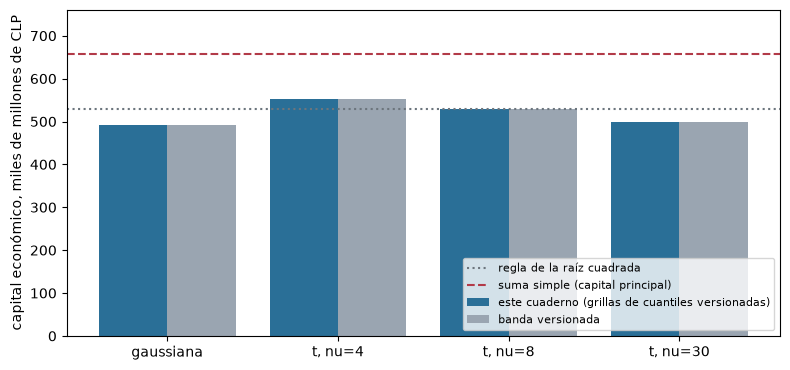

In [11]:
# Dibujar las cinco agregaciones con cópula aquí y en la banda versionada, con las dos filas cerradas como líneas de referencia
keys = list(here)
names = ["gaussiana" if k[1] is None else f"t, nu={k[1]:g}" for k in keys]
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [here[k].ec / 1e3 for k in keys], width=0.4, label="este cuaderno (grillas de cuantiles versionadas)", color="#2a6f97")
ax.bar(x + 0.2, [committed[k]["capital_clp_m"] / 1e3 for k in keys], width=0.4, label="banda versionada", color="#9aa5b1")
ax.axhline(total_vc / 1e3, color="#6c757d", linestyle=":", label="regla de la raíz cuadrada")
ax.axhline(agg["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--", label="suma simple (capital principal)")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("capital económico, miles de millones de CLP")
ax.set_ylim(0, 760)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

- **El coeficiente de la t cae rápido con los grados de libertad:** 0,2532 con $\nu = 4$, 0,1173 con $\nu = 8$ y 0,0030 con $\nu = 30$, por lo que $\nu = 30$ es el sustituto de la cópula gaussiana en el caso. En la simulación, la probabilidad de que el segundo riesgo también supere su cuantil 99,9 por ciento dado que lo supera el primero es 0,055 para la cópula gaussiana y 0,278 para la cópula t con $\nu = 4$; con un millón de simulaciones solo unos mil pares llegan a esa esquina, así que la estimación es una imagen del límite y no una medición de él.
- **Las marginales reconstruidas se leen como están versionadas.** Desde las grillas el motor lee el VaR versionado con error menor que 0,03 por ciento (crédito 298.239 frente a 298.227; riesgo operacional 42.357 frente a 42.367) y el ES versionado con error menor que 0,01 por ciento en crédito, mercado y riesgo de tasa de interés; el ES del riesgo operacional queda 1,5 por ciento sobre el versionado (173.668 frente a 171.091), porque la cifra versionada es `es_for_severity` del motor sobre la grilla de severidad y esta es el ES de una muestra de un millón de puntos de la grilla interpolada.
- **Las cuatro agregaciones reproducen las filas versionadas**: 491.999; 552.369; 528.318 y 499.133 frente a 491.974; 552.389; 528.321 y 499.128 (razones 1,000 para la cópula gaussiana y para las cópulas t con $\nu = 4$, 8 y 30), diferencias de 25, -20, -3 y 5 millones de CLP frente a errores estándar de Monte Carlo de 2.554 a 3.430, y **el orden es el versionado**: gaussiana, t con $\nu = 30$, 8 y luego 4. Las filas t quedan 1,5; 7,4 y 12,3 por ciento sobre la gaussiana, aquí y en la banda versionada.
- **La asignación del ES suma exactamente** (brecha relativa 0,0). El ES total es 709.403 frente a 709.390 versionado, y las participaciones son las versionadas: crédito 35,9 por ciento, mercado 38,9, riesgo de tasa de interés 11,1 y riesgo operacional 14,1 por ciento.
- **La asignación en forma cerrada de la regla de la raíz cuadrada suma 528.106**, el total del cuaderno 01, y da beneficios de Euler de 15,4 por ciento (crédito), 13,2 por ciento (mercado), 33,1 por ciento (riesgo de tasa de interés) y 68,8 por ciento (riesgo operacional): cuanto menor el riesgo, mayor su beneficio.

Lo que este cuaderno no muestra: las muestras de un millón de simulaciones mismas, que no están versionadas, así que las marginales salen de una grilla de 1.961 puntos y las filas coinciden hasta 0,01 por ciento y no hasta el último dígito; la cópula de Clayton, evaluada solo en forma cerrada porque el motor no la muestrea; y las filas gaussiana y t son condicionales a la matriz de correlación, una convención, cuyo estrés se lee en el cuaderno 07.

## Resumen

- Una cópula separa la dependencia de las marginales (Sklar); agregar es: elegir las marginales, elegir la cópula, simular $L_k = F_k^{-1}(U_k)$ y leer el VaR, el ES y el EC de la suma de la fila.
- La cópula gaussiana y la t comparten la misma correlación de rangos pero no la esquina: la t tiene dependencia de cola $\lambda = 2\,t_{\nu+1}(\cdot)$, la gaussiana ninguna, y una simulación muestra la diferencia.
- El documento de modelos versionado guarda la función de cuantiles de cada marginal sobre una grilla nombrada, no el millón de pérdidas; este cuaderno reconstruyó las marginales desde ella y las filas versionadas volvieron con error menor que 0,01 por ciento, en el orden versionado.
- La asignación de Euler del ES suma el total exactamente y da a cada riesgo un beneficio; la regla de la raíz cuadrada tiene una asignación en forma cerrada que también suma.

**Qué probar a continuación.** Cambia la semilla del paso 4 y mira moverse el capital en torno a su error estándar; luego sigue con el cuaderno 03, que agrega las dos cotas que no dependen de ninguna cópula: el mejor y el peor VaR sobre toda dependencia.

## Referencias

- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. y Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, en Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Li, D. X. (2000), la cópula gaussiana, y Frey, R. y McNeil, A. J. (2003) y Demarta, S. y McNeil, A. J. (2005), la cópula t, como los cita el docstring del módulo `riskvalidation.aggregation.copulas` del motor.
- Este repositorio: `docs/contracts/engine/aggregation-api.md`.